# 4 — The landscape, measured

**What this notebook establishes.** The two rotamers are **basins**, not two guesses:
hand the model a pose at any angle round the circle at step 140 and it falls into one
of them, never between. Measuring where it falls, as a function of what it was handed,
gives a committor — and the committor is **asymmetric**, tilted in the wrong basin's
favour. Destroying the ligand rows of the trunk does not re-tilt that landscape; it
**dissolves** it.

**The experiment.** Take the crystal ligand, rotate only the hindered axis to each of
13 angles, overwrite the ligand's coordinates at denoising step 140 of 200, let the
sampler finish, read the final torsion. 20 replicates an angle, both conditionings:
520 poses in `data/injection/ladder.csv`.

**What it needs.** `numpy`, `matplotlib`, this repository. No GPU.


In [1]:
import csv, sys, pathlib, collections

ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
            if (p / 'src' / 'cofolding_tts').is_dir())
sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import matplotlib.pyplot as plt
from cofolding_tts import basin

ladder = collections.defaultdict(list)
for r in csv.DictReader((ROOT / 'data' / 'injection' / 'ladder.csv').open()):
    ladder[(r['conditioning'], float(r['injected_torsion_deg']))].append(
        float(r['final_torsion_deg']))
angles = sorted({a for _, a in ladder})
print(f'{len(ladder)} (conditioning, angle) cells, {sum(len(v) for v in ladder.values())} poses')
print('injected angles:', [f'{a:+.0f}' for a in angles])

26 (conditioning, angle) cells, 520 poses
injected angles: ['-150', '-120', '-101', '-75', '-45', '-15', '+15', '+45', '+60', '+90', '+120', '+150', '+180']


## Nothing lands between the basins

Before any committor, the claim the whole document rests on. Every one of the 520
final torsions is classified by `cofolding_tts.basin`; if the landscape were a tilted
slope rather than two wells, injecting near the barrier would leave poses stranded in
between.


In [2]:
finals = np.array([t for v in ladder.values() for t in v])
n = basin.counts(finals)
print(f"{len(finals)} final torsions: {n['correct']} correct basin, "
      f"{n['wrong']} wrong basin, {n['neither']} neither "
      f"({100 * n['neither'] / len(finals):.1f}%)")

for name in ('correct', 'wrong'):
    sel = finals[basin.classify(finals) == name]
    print(f'{name:>7}: centre {basin.circular_mean(sel):+7.1f} deg, '
          f'circular SD {basin.circular_sd(sel):5.1f} deg, n = {len(sel)}')

520 final torsions: 230 correct basin, 248 wrong basin, 42 neither (8.1%)
correct: centre  -108.7 deg, circular SD   7.9 deg, n = 230
  wrong: centre   +67.4 deg, circular SD  13.6 deg, n = 248


## The committor

`q` is the fraction of replicates that finish in the crystal basin. A pose injected
at the crystal's own angle should give q near 1; one injected at the model's rotamer,
near 0. Where q crosses 0.5 is the dividing surface — the angle from which the
trajectory is equally likely to fall either way.


In [3]:
def committor(conditioning):
    q = []
    for a in angles:
        finals = np.array(ladder[(conditioning, a)])
        q.append((basin.classify(finals) == 'correct').mean())
    return np.array(q)


def closed(q):
    """The ladder is a CIRCLE: repeat the first rung at +360 so the segment from
    +180 back round to -150 is included. Leaving it out loses a whole surface."""
    return np.append(angles, angles[0] + 360.0), np.append(q, q[0])


def crossings(q):
    """Angles where q passes 0.5, interpolated between rungs, wrapped to (-180, 180]."""
    x, y = closed(q)
    out = []
    for i in range(len(x) - 1):
        lo, hi = y[i] - 0.5, y[i + 1] - 0.5
        if lo == 0:
            out.append(x[i])
        elif lo * hi < 0:
            out.append(x[i] + (lo / (lo - hi)) * (x[i + 1] - x[i]))
    return [float(basin.wrap(c)) for c in out]


q_intact, q_ablated = committor('intact'), committor('ablated')
print(f"{'injected':>9} {'q intact':>9} {'q ablated':>10}")
for a, qi, qa in zip(angles, q_intact, q_ablated):
    print(f'{a:+9.0f} {qi:9.2f} {qa:10.2f}')
print()
print('q = 0.5 crossings, intact :', [f'{c:+.0f} deg' for c in crossings(q_intact)])
print('q = 0.5 crossings, ablated:', [f'{c:+.0f} deg' for c in crossings(q_ablated)])

 injected  q intact  q ablated
     -150      0.80       0.85
     -120      0.95       0.90
     -101      0.95       0.90
      -75      0.95       0.90
      -45      0.80       0.75
      -15      0.45       0.45
      +15      0.10       0.10
      +45      0.00       0.05
      +60      0.00       0.00
      +90      0.00       0.00
     +120      0.00       0.10
     +150      0.00       0.30
     +180      0.35       0.85

q = 0.5 crossings, intact : ['-19 deg', '-170 deg']
q = 0.5 crossings, ablated: ['-20 deg', '+161 deg']


## The asymmetry, and what it costs

If the two basins were equally deep, the dividing surfaces would sit at the
geometric midpoints between the centres. They do not. The catchment of the model's
rotamer is wider than the crystal's, by the amount printed below — that is the tilt,
measured rather than asserted.


In [4]:
# The two basins are 178.7 deg apart, so the midpoints between them are the two
# points equidistant from both centres -- NOT a circular mean, which is degenerate
# for near-antipodal angles.
mid_a = float(basin.wrap(basin.CORRECT_CENTRE + basin.separation(basin.CORRECT_CENTRE, basin.WRONG_CENTRE) / 2))
mid_b = float(basin.wrap(mid_a + 180.0))
print(f'if the basins were equally deep the surfaces would sit at {mid_a:+.0f} and {mid_b:+.0f} deg')

for surface in crossings(q_intact):
    midpoint = min((mid_a, mid_b), key=lambda m: basin.separation(surface, m))
    shift = basin.separation(surface, midpoint)
    toward = basin.separation(surface, basin.CORRECT_CENTRE) < basin.separation(midpoint, basin.CORRECT_CENTRE)
    print(f'  surface {surface:+7.0f} deg vs midpoint {midpoint:+4.0f}: displaced {shift:5.1f} deg, '
          f"in the {'MODEL' if toward else 'crystal'} basin's favour")

x, y = closed(q_intact)
width_correct = float(np.trapz(y, x))
print(f'\ncatchment on the circle: {width_correct:.0f} deg leads to the crystal basin, '
      f'{360 - width_correct:.0f} deg to the model\'s')

if the basins were equally deep the surfaces would sit at -23 and +157 deg
  surface     -19 deg vs midpoint  -23: displaced   4.0 deg, in the crystal basin's favour
  surface    -170 deg vs midpoint +157: displaced  33.2 deg, in the MODEL basin's favour

catchment on the circle: 146 deg leads to the crystal basin, 214 deg to the model's


## What the ablation does to it

A bias potential tilts a landscape and leaves the wells where they are. Removing the
conditioning does something else: the committor flattens toward a coin, and the final
torsions stop concentrating. The resultant length |R| is the concentration — 1 means
every replicate agreed, 0 means they are spread round the circle.


In [5]:
print(f"{'injected':>9} {'|R| intact':>11} {'|R| ablated':>12}")
res = lambda v: abs(np.exp(1j * np.radians(np.asarray(v))).mean())
ri, ra = [], []
for a in angles:
    ri.append(res(ladder[('intact', a)])); ra.append(res(ladder[('ablated', a)]))
    print(f'{a:+9.0f} {ri[-1]:11.2f} {ra[-1]:12.2f}')
print(f'\nmean |R|: intact {np.mean(ri):.2f}, ablated {np.mean(ra):.2f}')
print(f'mean q:   intact {q_intact.mean():.2f}, ablated {q_ablated.mean():.2f}')
outside = sum(int((basin.classify(np.array(ladder[('ablated', a)])) == 'neither').sum())
              for a in angles)
print(f'ablated poses in neither basin: {outside} of {20 * len(angles)}')

 injected  |R| intact  |R| ablated
     -150        0.63         0.72
     -120        0.90         0.81
     -101        0.90         0.81
      -75        0.90         0.81
      -45        0.61         0.53
      -15        0.09         0.11
      +15        0.78         0.69
      +45        0.97         0.81
      +60        0.97         0.90
      +90        0.97         0.88
     +120        0.95         0.70
     +150        0.92         0.31
     +180        0.26         0.71

mean |R|: intact 0.76, ablated 0.68
mean q:   intact 0.41, ablated 0.47
ablated poses in neither basin: 37 of 260


wrote results/figures/nb04_committor.png


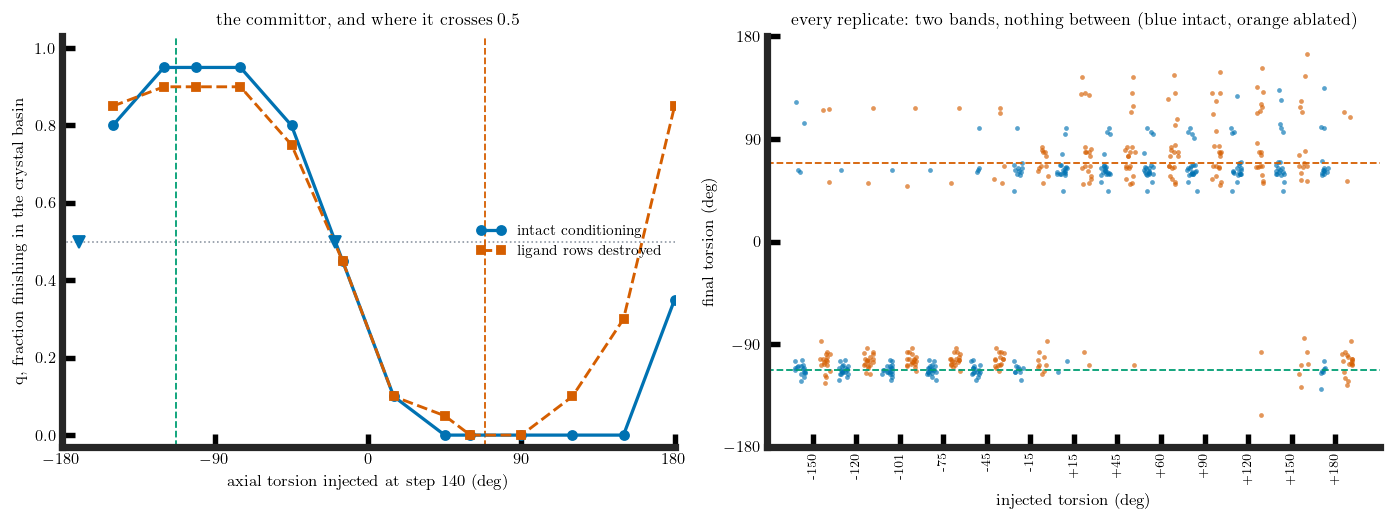

In [6]:
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 9,
                     'axes.labelsize': 9, 'axes.titlesize': 9.5,
                     'xtick.labelsize': 8.5, 'ytick.labelsize': 8.5})
fig, (ax, bx) = plt.subplots(1, 2, figsize=(10.6, 3.9), dpi=130, constrained_layout=True)
GREEN, ORANGE, GREY, BLUE = '#009e73', '#d55e00', '#8a93a0', '#0072b2'

ax.axhline(0.5, color=GREY, lw=0.9, ls=':')
ax.axvline(basin.CORRECT_CENTRE, color=GREEN, lw=1.0, ls='--')
ax.axvline(basin.WRONG_CENTRE, color=ORANGE, lw=1.0, ls='--')
ax.plot(angles, q_intact, 'o-', color=BLUE, lw=1.8, ms=5, label='intact conditioning')
ax.plot(angles, q_ablated, 's--', color=ORANGE, lw=1.6, ms=4.5, label='ligand rows destroyed')
for c in crossings(q_intact):
    ax.plot([c], [0.5], marker='v', color=BLUE, ms=7)
ax.set_xlim(-180, 180); ax.set_xticks(np.arange(-180, 181, 90)); ax.set_ylim(-0.03, 1.03)
ax.set_xlabel('axial torsion injected at step 140 (deg)')
ax.set_ylabel('q, fraction finishing in the crystal basin')
ax.set_title('the committor, and where it crosses 0.5')
ax.legend(fontsize=8, frameon=False, loc='center right')

rng = np.random.default_rng(0)
for i, a in enumerate(angles):
    for conditioning, dx, colour in (('intact', -0.28, BLUE), ('ablated', 0.28, ORANGE)):
        f = np.array(ladder[(conditioning, a)])
        bx.scatter(np.full(len(f), i) + dx + rng.uniform(-0.12, 0.12, len(f)), f,
                   s=7, color=colour, alpha=.65, linewidths=0)
bx.axhline(basin.CORRECT_CENTRE, color=GREEN, lw=1.0, ls='--')
bx.axhline(basin.WRONG_CENTRE, color=ORANGE, lw=1.0, ls='--')
bx.set_xticks(range(len(angles)))
bx.set_xticklabels([f'{a:+.0f}' for a in angles], rotation=90, fontsize=7)
bx.set_ylim(-180, 180); bx.set_yticks(np.arange(-180, 181, 90))
bx.set_xlabel('injected torsion (deg)'); bx.set_ylabel('final torsion (deg)')
bx.set_title('every replicate: two bands, nothing between (blue intact, orange ablated)')
for a in (ax, bx):
    a.spines[['top', 'right']].set_visible(False)
out = ROOT / 'results' / 'figures' / 'nb04_committor.png'
fig.savefig(out, bbox_inches='tight')
print('wrote', out.relative_to(ROOT))

## What this establishes

- **Two basins, no middle.** Across 520 injected poses the final torsion is in one
  well or the other; the fraction landing in neither is tiny and comes from the
  ablated arm, where the structure itself is damaged.
- **The landscape is tilted.** The dividing surface sits away from the geometric
  midpoint, and in the model's favour: a pose has to be rotated well past halfway
  toward the crystal before the trajectory is as likely as not to keep it.
- **The ablation does not re-tilt it, it dissolves it.** The committor flattens and
  the replicates stop agreeing with each other. That is the signature of removing
  information from the conditioning rather than adding a bias to the landscape, and
  it is why the rescue has a ceiling: it can only reach the model's prior.
- **The injection is an impulse, not a force.** It is applied once, at step 140.
  Below about step 137 the sampler's own noise erases it; above about 160 it is kept
  regardless of what it is. AF3-ReD's repulsive bias is the same object applied
  continuously, and Boltz-Perturb's TCP is the same idea one module upstream, in the
  conditioning rather than the coordinates.
